<a href="https://colab.research.google.com/github/sejal-oli7/Elevvo-Machine-Learning-Internship/blob/main/Loan_Approval_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay)

try:
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline as ImbPipeline
except ImportError:
    !pip install -q imbalanced-learn
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 42
sns.set_style("whitegrid")

In [2]:
CSV_PATH = "/content/loan_approval_dataset.csv"

df = pd.read_csv(CSV_PATH)
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (4269, 13)


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [13]:


df.columns = df.columns.str.strip().str.lower()
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

df = df.drop(columns=["loan_id"], errors="ignore")
print(df.shape)
print(df.columns.tolist())

(4269, 12)
['no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'loan_status']


In [14]:
print("Missing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.describe()

Missing values:
 no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64

Duplicate rows: 0


,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64
loan_status
Approved    62.2 %
Rejected    37.8 %
Name: proportion, dtype: object


/tmp/ipykernel_2392/922903966.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="loan_status", palette="Set2")


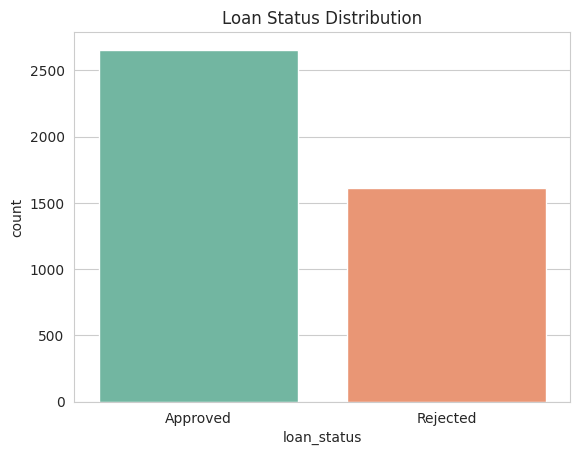

In [15]:
counts = df["loan_status"].value_counts()
print(counts)
print((df["loan_status"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")

sns.countplot(data=df, x="loan_status", palette="Set2")
plt.title("Loan Status Distribution")
plt.show()

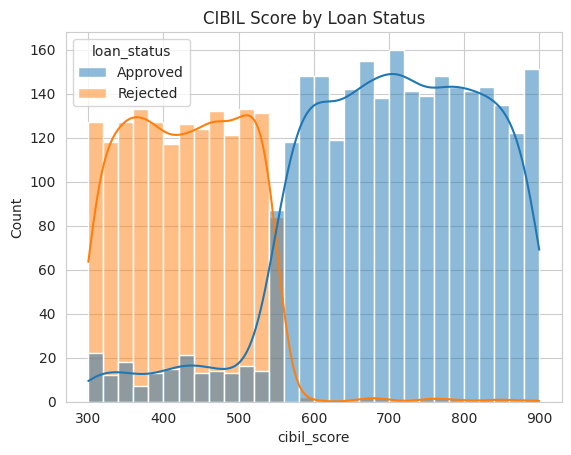

In [16]:
sns.histplot(data=df, x="cibil_score", hue="loan_status", bins=30, kde=True)
plt.title("CIBIL Score by Loan Status")
plt.show()

/tmp/ipykernel_2392/4158932216.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="loan_status", y=col, ax=ax, palette="Set2")
/tmp/ipykernel_2392/4158932216.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="loan_status", y=col, ax=ax, palette="Set2")
/tmp/ipykernel_2392/4158932216.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="loan_status", y=col, ax=ax, palette="Set2")
/tmp/ipykernel_2392/4158932216.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed 

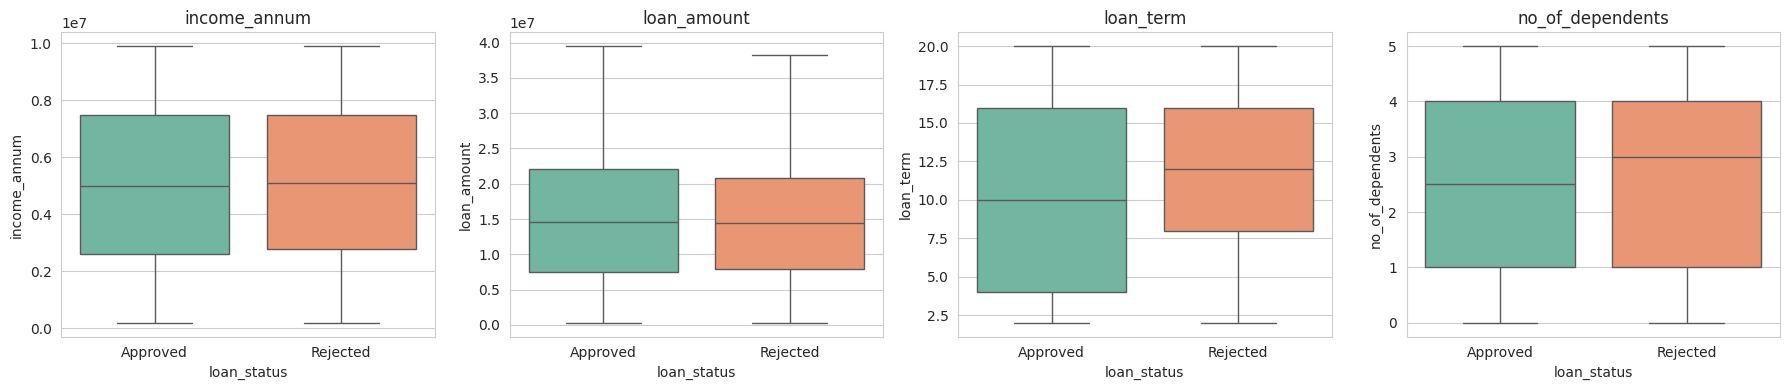

In [19]:

num_features = ["income_annum", "loan_amount", "loan_term", "no_of_dependents"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, num_features):
    sns.boxplot(data=df, x="loan_status", y=col, ax=ax, palette="Set2")
    ax.set_title(col)
plt.tight_layout()
plt.show()

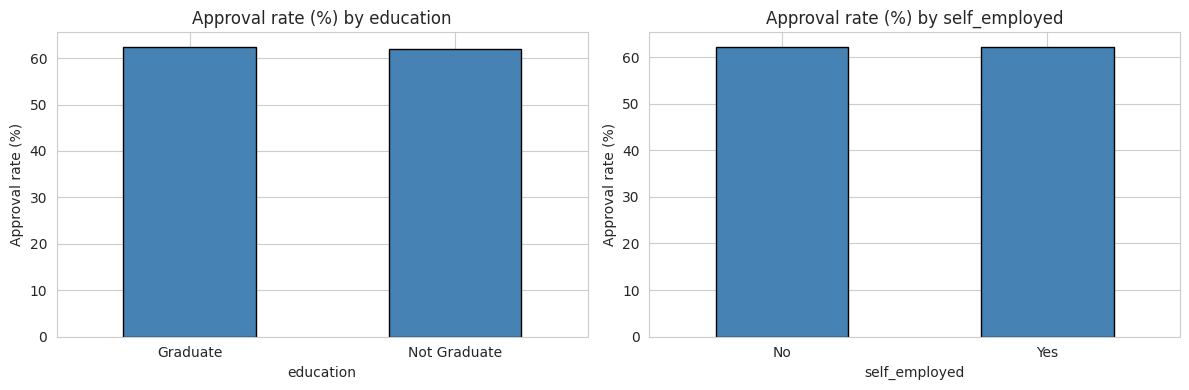

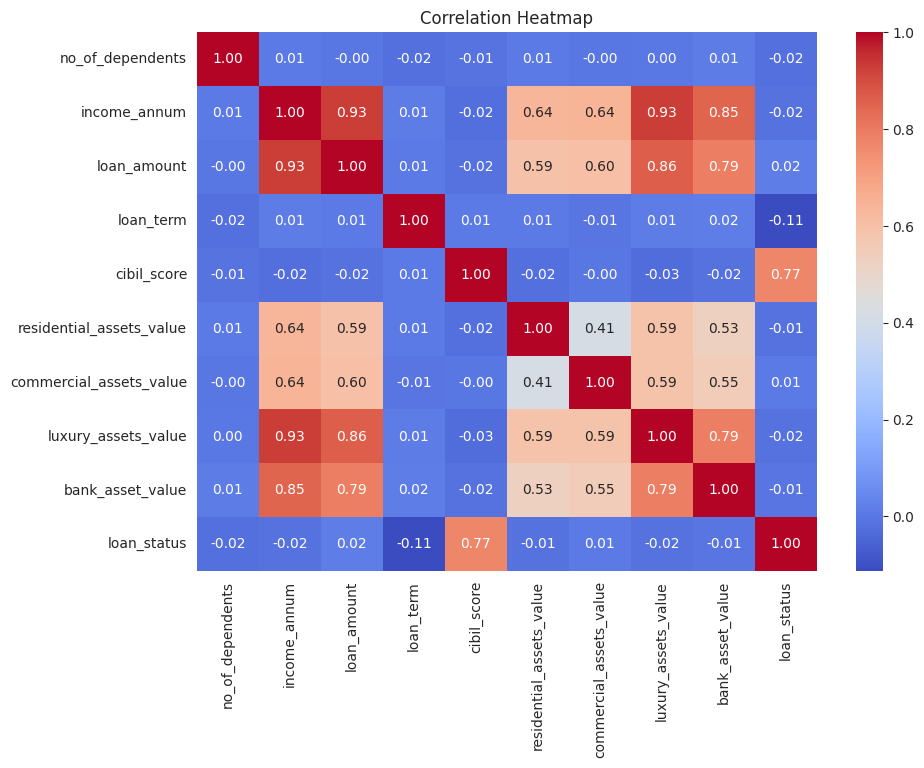

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["education", "self_employed"]):
    rate = (df["loan_status"] == "Approved").groupby(df[col]).mean() * 100
    rate.plot(kind="bar", ax=ax, color="steelblue", edgecolor="black")
    ax.set_title(f"Approval rate (%) by {col}")
    ax.set_ylabel("Approval rate (%)")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

tmp = df.copy()
tmp["loan_status"] = (tmp["loan_status"] == "Approved").astype(int)
plt.figure(figsize=(10, 7))
sns.heatmap(tmp.select_dtypes(include="number").corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [21]:
y = df["loan_status"].map({"Approved": 1, "Rejected": 0})
X = df.drop(columns="loan_status")
assert y.notna().all(), "Unexpected values in loan_status"

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Approved share  train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (3415, 11) | Test: (854, 11)
Approved share  train: 0.622 | test: 0.622


In [22]:
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print("Numeric:", num_cols)
print("Categorical:", cat_cols)

def make_preprocessor():
    num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                         ("scaler", StandardScaler())])
    cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                         ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num_pipe, num_cols),
                              ("cat", cat_pipe, cat_cols)])

Numeric: ['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']
Categorical: ['education', 'self_employed']


In [23]:
models = {
    "LogReg": Pipeline([("prep", make_preprocessor()),
                        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
    "LogReg (balanced)": Pipeline([("prep", make_preprocessor()),
                        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced",
                                                   random_state=RANDOM_STATE))]),
    "LogReg + SMOTE": ImbPipeline([("prep", make_preprocessor()),
                        ("smote", SMOTE(random_state=RANDOM_STATE)),
                        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
    "Decision Tree": Pipeline([("prep", make_preprocessor()),
                        ("clf", DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE))]),
    "Decision Tree + SMOTE": ImbPipeline([("prep", make_preprocessor()),
                        ("smote", SMOTE(random_state=RANDOM_STATE)),
                        ("clf", DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE))]),
}

for name, model in models.items():
    model.fit(X_train, y_train)
print("All models trained.")

All models trained.


In [24]:
rows = []
for name, model in models.items():
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (Approved)": precision_score(y_test, pred, pos_label=1),
        "Recall (Approved)": recall_score(y_test, pred, pos_label=1),
        "F1 (Approved)": f1_score(y_test, pred, pos_label=1),
        "Precision (Rejected)": precision_score(y_test, pred, pos_label=0),
        "Recall (Rejected)": recall_score(y_test, pred, pos_label=0),
        "F1 (Rejected)": f1_score(y_test, pred, pos_label=0),
        "Macro F1": f1_score(y_test, pred, average="macro"),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })

results = pd.DataFrame(rows).set_index("Model").round(3)
results.sort_values("Macro F1", ascending=False)

,Accuracy,Precision (Approved),Recall (Approved),F1 (Approved),Precision (Rejected),Recall (Rejected),F1 (Rejected),Macro F1,ROC-AUC
Model,,,,,,,,,
Decision Tree + SMOTE,0.971,0.987,0.966,0.976,0.946,0.978,0.962,0.969,0.992
Decision Tree,0.968,0.983,0.966,0.974,0.946,0.972,0.959,0.967,0.988
LogReg (balanced),0.924,0.955,0.921,0.938,0.877,0.929,0.902,0.920,0.973
LogReg + SMOTE,0.923,0.951,0.923,0.937,0.879,0.923,0.900,0.919,0.973
LogReg,0.915,0.921,0.944,0.932,0.903,0.867,0.885,0.908,0.973


In [25]:
for name, model in models.items():
    print("=" * 60)
    print(name)
    print(classification_report(y_test, model.predict(X_test),
                                target_names=["Rejected", "Approved"], digits=3))

LogReg
              precision    recall  f1-score   support

    Rejected      0.903     0.867     0.885       323
    Approved      0.921     0.944     0.932       531

    accuracy                          0.915       854
   macro avg      0.912     0.905     0.908       854
weighted avg      0.914     0.915     0.914       854

LogReg (balanced)
              precision    recall  f1-score   support

    Rejected      0.877     0.929     0.902       323
    Approved      0.955     0.921     0.938       531

    accuracy                          0.924       854
   macro avg      0.916     0.925     0.920       854
weighted avg      0.926     0.924     0.924       854

LogReg + SMOTE
              precision    recall  f1-score   support

    Rejected      0.879     0.923     0.900       323
    Approved      0.951     0.923     0.937       531

    accuracy                          0.923       854
   macro avg      0.915     0.923     0.919       854
weighted avg      0.924     0.923 

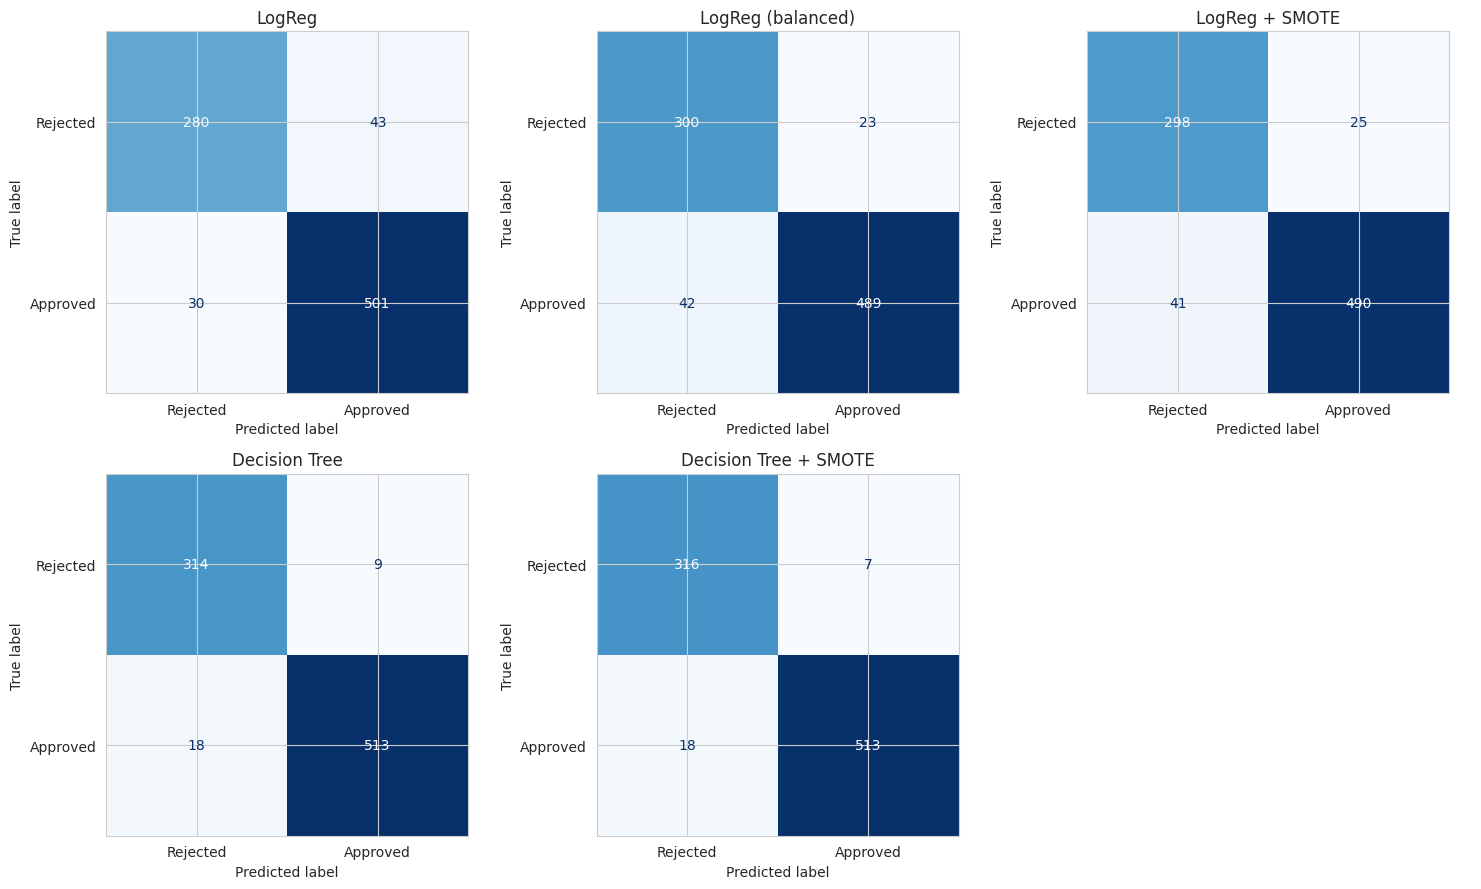

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, model) in zip(axes.ravel(), models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test,
        display_labels=["Rejected", "Approved"], cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)
for ax in axes.ravel()[len(models):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

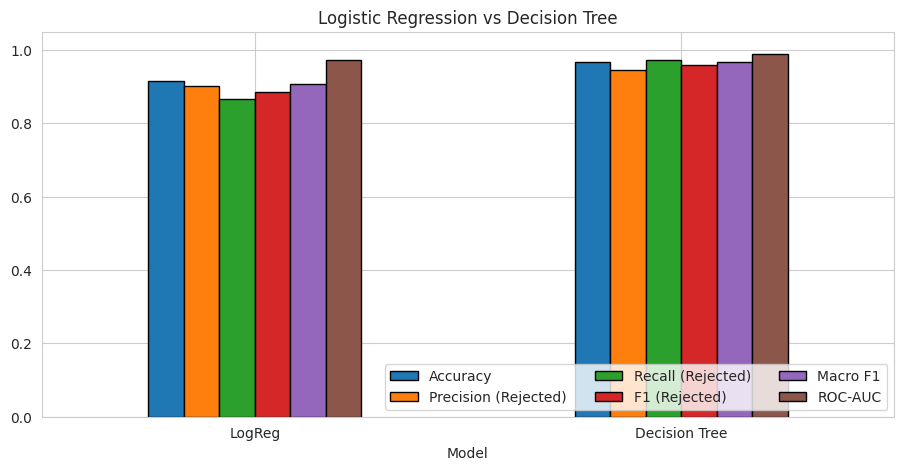

,Accuracy,Precision (Rejected),Recall (Rejected),F1 (Rejected),Macro F1,ROC-AUC
Model,,,,,,
LogReg,0.915,0.903,0.867,0.885,0.908,0.973
Decision Tree,0.968,0.946,0.972,0.959,0.967,0.988


In [27]:
compare = results.loc[["LogReg", "Decision Tree"],
                      ["Accuracy", "Precision (Rejected)", "Recall (Rejected)", "F1 (Rejected)", "Macro F1", "ROC-AUC"]]
compare.plot(kind="bar", figsize=(11, 5), edgecolor="black")
plt.title("Logistic Regression vs Decision Tree")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right", ncol=3)
plt.show()
compare

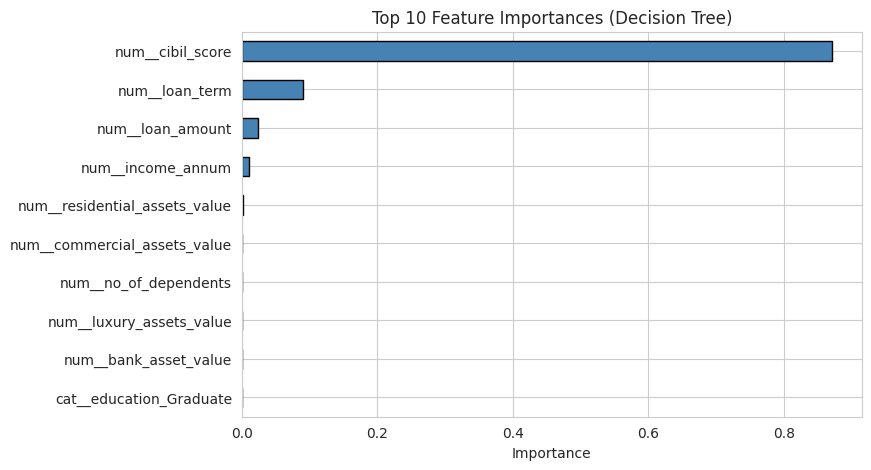

,0
num__cibil_score,0.872
num__loan_term,0.091
num__loan_amount,0.024
num__income_annum,0.011
num__residential_assets_value,0.002
num__commercial_assets_value,0.000
num__no_of_dependents,0.000
num__luxury_assets_value,0.000
num__bank_asset_value,0.000
cat__education_Graduate,0.000


In [28]:
tree_pipe = models["Decision Tree"]
names = tree_pipe.named_steps["prep"].get_feature_names_out()
importances = pd.Series(tree_pipe.named_steps["clf"].feature_importances_, index=names)
top = importances.sort_values(ascending=False).head(10)

top[::-1].plot(kind="barh", color="steelblue", edgecolor="black", figsize=(8, 5))
plt.title("Top 10 Feature Importances (Decision Tree)")
plt.xlabel("Importance")
plt.show()
top.round(3)

In [29]:
best = results["Macro F1"].idxmax()
print("Best model by Macro F1:", best)
print(results.loc[best].to_string())
print("\nBest Rejected-class F1:", results["F1 (Rejected)"].idxmax(),
      "| Best Rejected-class recall:", results["Recall (Rejected)"].idxmax())

Best model by Macro F1: Decision Tree + SMOTE
Accuracy                0.971
Precision (Approved)    0.987
Recall (Approved)       0.966
F1 (Approved)           0.976
Precision (Rejected)    0.946
Recall (Rejected)       0.978
F1 (Rejected)           0.962
Macro F1                0.969
ROC-AUC                 0.992

Best Rejected-class F1: Decision Tree + SMOTE | Best Rejected-class recall: Decision Tree + SMOTE


## Conclusion

- The dataset has 4,269 applications with no missing values and no duplicates. 62.2% of the loans were approved and 37.8% rejected, so the imbalance is mild.
- The Decision Tree (max depth 5) beat Logistic Regression on every metric: Macro F1 0.967 vs 0.908 and ROC-AUC 0.988 vs 0.973.
- For Logistic Regression, SMOTE and class weights raised the recall of the Rejected class (0.867 to 0.923 and 0.929) but lowered its precision (0.903 to 0.879 and 0.877). The Rejected F1 improved slightly (0.885 to about 0.90).
- For the Decision Tree, SMOTE changed little (Macro F1 0.967 to 0.969). On a test set of 854 rows this difference is too small to call a real improvement.
- The CIBIL score is by far the most important feature (importance 0.872), followed by loan term (0.091). The model relies almost entirely on the credit score.
- Best model by Macro F1: Decision Tree + SMOTE, with precision 0.946, recall 0.978 and F1 0.962 for the Rejected class.